# Digital Logic Circuit Designer: Discrete Mathematics for Computer Engineering

**Course:** CPEN 213 – Discrete Mathematics (Level 200, Semester 1)
**Project type:** Course project – design, verification and analysis in Python
**Tools:** Python 3 standard library and Matplotlib – everything runs in Google Colab with no extra installation.

---

## 1. Project description

Every processor, phone and embedded controller is built from **logic gates**: AND, OR, NOT, XOR and NAND. Designing these circuits is applied discrete mathematics:
* Inputs and outputs are **sets** of bit patterns.
* A circuit's behaviour is a **Boolean function**, written in **propositional logic** and specified by a **truth table**.
* Large circuits are built **recursively** from small ones, and their cost and delay follow **recurrence relations**.
* Correctness for *every* input size needs a **proof**, usually by **induction**.
* **Counting**, **permutations, combinations** and **generating functions** tell us how many designs, inputs and code words exist.

In this project we design, minimise, prove correct and analyse the logic for a small digital system using every topic from CPEN 213.

### Problem statement
A computer engineering team is building a small **arithmetic and safety unit** for an embedded controller. It needs four blocks:

1. **A majority voter** for a fault-tolerant sensor system (triple modular redundancy). Three sensors vote, and the output follows the majority, so one faulty sensor cannot cause a wrong decision.
2. **A full adder and an n-bit ripple-carry adder** for arithmetic.
3. **A parity generator** that adds an error-detection bit to every data word.
4. **A Gray-code position encoder**, where consecutive positions differ in only one bit, to avoid glitches.

To build these blocks, the team must answer these questions:

* **Specification:** How can each block's behaviour be stated precisely and without ambiguity?
* **Minimisation:** What is the smallest circuit that implements each block, and how can we be sure it is equivalent to the specification?
* **Structure:** Which formulas are equivalent? Which gate sets can build *any* circuit, and which cannot?
* **Scale:** How many inputs, functions and possible designs exist? Why is exhaustive testing impossible for a 64-bit adder?
* **Growth:** How do the gate count and delay grow as the circuits get bigger?
* **Correctness:** How can we *prove* that the adder works for every word size, not just the sizes we test?
* **Codes and parts:** How many valid code words satisfy a constraint, and how many ways can chips be combined to supply the gates needed?

The task is to answer each question with the methods of discrete mathematics. Every result is computed in Python and checked by brute force.

### Objectives
1. Use **sets, Venn diagrams, power sets and complements** to describe inputs and Boolean functions.
2. Use **propositional logic and truth tables** to specify circuits and verify logical laws.
3. Classify circuits as **functions** (injective, surjective, inverse) and study **relations** on formulas (equivalence relations, partial orders).
4. Minimise circuits with the Quine–McCluskey method, using set operations and **combinations**.
5. Apply **counting principles, permutations and combinations** to inputs, functions and test plans.
6. Build circuits **recursively** and analyse them with **recurrence relations**.
7. Prove properties with **mathematical induction**, **proof by contradiction**, proof by exhaustion and constructive proof.
8. Solve counting problems with **generating functions**.

### Course topics mapped to notebook sections

| # | Section | CPEN 213 topics used |
|---|---|---|
| 2 | Inputs and functions as sets | Sets, set operations, Venn diagrams, complements, power sets, inclusion–exclusion |
| 3 | Specifying circuits | Propositional logic, connectives, truth tables, tautologies and contradictions, logical equivalence, laws of logic |
| 4 | Circuits as functions; relations on formulas | Functions (domain, codomain, image, injective, surjective, inverse, composition), relations (equivalence relations and classes, partial orders) |
| 5 | Designing and minimising circuits | Truth tables → sum of products, set-based minimisation, combinations to find the minimal cover |
| 6 | Counting | Sum and product rules, permutations, combinations, pigeonhole principle, brute-force checks |
| 7 | Recursive circuits | Recursion: input generation, Gray code, ripple-carry adder, multiplexer tree |
| 8 | Cost and delay | Recurrence relations: unrolling, characteristic equation, divide and conquer, memoisation |
| 9 | Proving circuits correct | Mathematical induction, proof by contradiction, proof by exhaustion, constructive proof |
| 10 | Codes and parts | Generating functions: binomial, rational and product generating functions |
| 11 | Final design and conclusion | Summary of the complete unit |

### How to run
Open this notebook in Google Colab and choose **Runtime → Run all**. Every section builds on the functions defined in earlier sections.

## 1. Setup and helper functions

In [1]:
from itertools import combinations, product, permutations
from functools import lru_cache
from math import comb, perm, factorial, ceil, log2
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})

def all_inputs(n):
    # Recursively lists every n-bit input as a tuple, in binary counting order
    if n == 0:
        return [()]
    smaller = all_inputs(n - 1)
    return [bits + (b,) for bits in smaller for b in (0, 1)]

# Extra logical connectives
def IMP(p, q):  return (not p) or q          # implication  p → q
def IFF(p, q):  return bool(p) == bool(q)    # biconditional p ↔ q
def XOR(p, q):  return bool(p) != bool(q)    # exclusive or

def formula(expr, names):
    # Turns a logic expression such as "a and not b" into a Boolean function of the named variables
    env = {"__builtins__": {}, "IMP": IMP, "IFF": IFF, "XOR": XOR}
    return lambda *vals: bool(eval(expr, env, dict(zip(names, map(bool, vals)))))

def truth_table(f, n):
    return tuple(int(bool(f(*bits))) for bits in all_inputs(n))

def print_truth_table(names, outputs):
    # outputs: {column label: function}
    header = " ".join(names) + " | " + "  ".join(outputs)
    print(header)
    print("-" * len(header))
    for bits in all_inputs(len(names)):
        vals = [int(bool(f(*bits))) for f in outputs.values()]
        print(" ".join(map(str, bits)) + " | " + "  ".join(f"{v:>{len(k)}}" for k, v in zip(outputs, vals)))

print("All 3-bit inputs:", all_inputs(3))

All 3-bit inputs: [(0, 0, 0), (0, 0, 1), (0, 1, 0), (0, 1, 1), (1, 0, 0), (1, 0, 1), (1, 1, 0), (1, 1, 1)]


## 2. Inputs and functions as sets

### 2.1 The universal set and the logic–set dictionary
For a 3-input circuit, the **universal set** is $U = \{0,1\}^3$, the 8 possible input patterns. Let $A$, $B$, $C$ be the sets of inputs where $a=1$, $b=1$ and $c=1$. A Boolean function $f$ is fully described by its **on-set** $\{x \in U : f(x) = 1\}$, and the logic operations become set operations:

| Logic | Set operation |
|---|---|
| $p \land q$ (AND) | intersection $P \cap Q$ |
| $p \lor q$ (OR) | union $P \cup Q$ |
| $\lnot p$ (NOT) | complement $\overline{P} = U \setminus P$ |
| $p \oplus q$ (XOR) | symmetric difference $P \,\triangle\, Q$ |

In [2]:
NAMES3 = ["a", "b", "c"]
U = set(all_inputs(3))
A = {x for x in U if x[0] == 1}
B = {x for x in U if x[1] == 1}
C = {x for x in U if x[2] == 1}

def on_set(f, n):
    return {x for x in all_inputs(n) if f(*x)}

checks = {
    "a and b      ↔  A ∩ B": on_set(formula("a and b", NAMES3), 3) == A & B,
    "a or b       ↔  A ∪ B": on_set(formula("a or b", NAMES3), 3) == A | B,
    "not a        ↔  U \\ A": on_set(formula("not a", NAMES3), 3) == U - A,
    "XOR(a, b)    ↔  A △ B": on_set(formula("XOR(a, b)", NAMES3), 3) == A ^ B,
}
for k, v in checks.items():
    print(f"{k}: {v}")

print("\nDe Morgan's laws for sets:")
print("  complement(A ∪ B) = Ā ∩ B̄ :", U - (A | B) == (U - A) & (U - B))
print("  complement(A ∩ B) = Ā ∪ B̄ :", U - (A & B) == (U - A) | (U - B))

# The majority voter: output 1 when at least two inputs are 1
MAJ = (A & B) | (A & C) | (B & C)
print("\nMajority on-set   =", sorted(MAJ))
print("Majority off-set  = complement =", sorted(U - MAJ))

# Inclusion–exclusion
lhs = len(A | B | C)
rhs = len(A) + len(B) + len(C) - len(A & B) - len(A & C) - len(B & C) + len(A & B & C)
print(f"\nInclusion–exclusion: |A ∪ B ∪ C| = {lhs},  formula gives {rhs}")

a and b      ↔  A ∩ B: True
a or b       ↔  A ∪ B: True
not a        ↔  U \ A: True
XOR(a, b)    ↔  A △ B: True

De Morgan's laws for sets:
  complement(A ∪ B) = Ā ∩ B̄ : True
  complement(A ∩ B) = Ā ∪ B̄ : True

Majority on-set   = [(0, 1, 1), (1, 0, 1), (1, 1, 0), (1, 1, 1)]
Majority off-set  = complement = [(0, 0, 0), (0, 0, 1), (0, 1, 0), (1, 0, 0)]

Inclusion–exclusion: |A ∪ B ∪ C| = 7,  formula gives 7


### 2.2 Venn diagrams of circuit behaviour
Each of the 8 regions of a three-set Venn diagram is exactly one input pattern (a **minterm**). Shading the regions in a function's on-set gives a picture of the circuit.

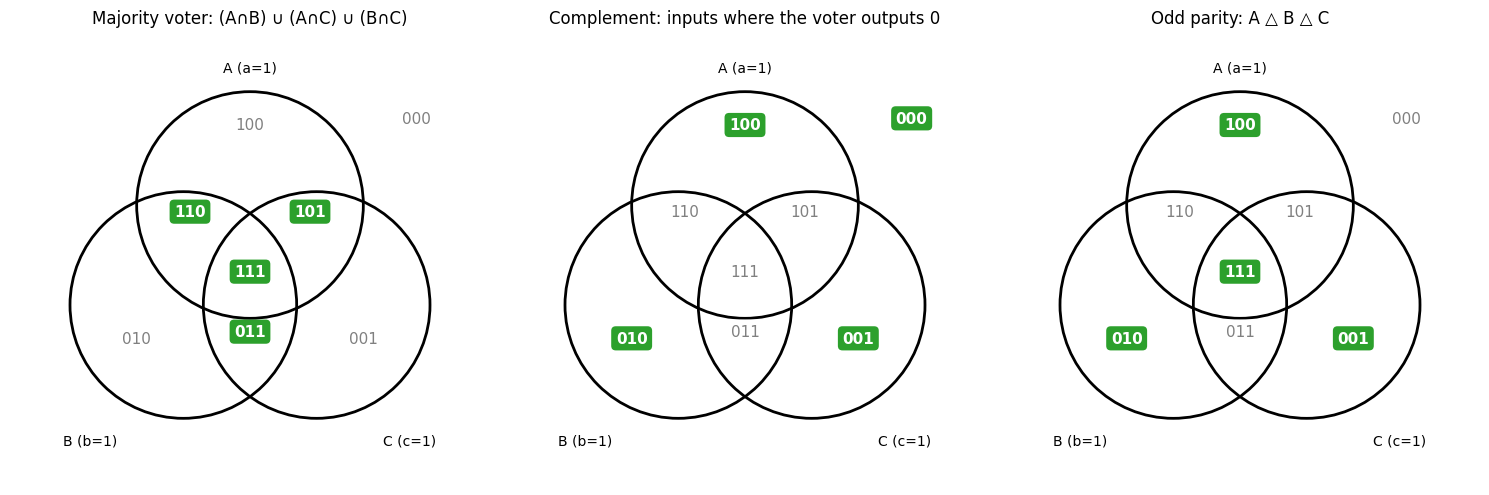

In [3]:
REGION_POS = {(1, 1, 1): (0, 0), (1, 1, 0): (-0.45, 0.45), (1, 0, 1): (0.45, 0.45), (0, 1, 1): (0, -0.45),
              (1, 0, 0): (0, 1.1), (0, 1, 0): (-0.85, -0.5), (0, 0, 1): (0.85, -0.5), (0, 0, 0): (1.25, 1.15)}

def draw_venn(ax, on, title):
    for (cx, cy), (lx, ly), label in [((0, 0.5), (0, 1.5), "A (a=1)"),
                                      ((-0.5, -0.25), (-1.2, -1.3), "B (b=1)"),
                                      ((0.5, -0.25), (1.2, -1.3), "C (c=1)")]:
        ax.add_patch(Circle((cx, cy), 0.85, fill=False, lw=2))
        ax.text(lx, ly, label, ha="center", fontsize=10)
    for bits, (x, y) in REGION_POS.items():
        inside = bits in on
        ax.text(x, y, "".join(map(str, bits)), ha="center", va="center", fontsize=11,
                fontweight="bold" if inside else "normal", color="white" if inside else "gray",
                bbox=dict(boxstyle="round", fc="tab:green" if inside else "white", ec="none"))
    ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.6, 1.8)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)

PARITY3 = on_set(formula("XOR(XOR(a, b), c)", NAMES3), 3)
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
draw_venn(axs[0], MAJ, "Majority voter: (A∩B) ∪ (A∩C) ∪ (B∩C)")
draw_venn(axs[1], U - MAJ, "Complement: inputs where the voter outputs 0")
draw_venn(axs[2], PARITY3, "Odd parity: A △ B △ C")
plt.tight_layout()
plt.show()

### 2.3 Power sets: every subset is a circuit
Every subset of $U$ is the on-set of exactly one Boolean function. So the set of all 3-input functions is in one-to-one correspondence with the **power set** $\mathcal P(U)$, and there are $|\mathcal P(U)| = 2^{|U|} = 2^8 = 256$ of them. We build the power set **recursively**: the subsets of $S$ are the subsets of $S \setminus \{s\}$, each taken with and without $s$.

In [4]:
def power_set(S):
    S = list(S)
    if not S:
        return [set()]
    first, rest = S[0], power_set(S[1:])
    return rest + [subset | {first} for subset in rest]

print("Power set of {a, b}:", power_set(["a", "b"]))
P_U = power_set(sorted(U))
print(f"|P(U)| = {len(P_U)} = 2^{len(U)} = {2 ** len(U)} Boolean functions of 3 inputs")
print("Is the majority on-set in P(U)?", MAJ in P_U)

Power set of {a, b}: [set(), {'b'}, {'a'}, {'b', 'a'}]
|P(U)| = 256 = 2^8 = 256 Boolean functions of 3 inputs
Is the majority on-set in P(U)? True


## 3. Specifying circuits: propositional logic and truth tables

### 3.1 Connectives and truth tables
A **truth table** lists the output for every combination of inputs. It is a complete, unambiguous specification of a circuit.

In [5]:
NAMES2 = ["p", "q"]
print_truth_table(NAMES2, {
    "¬p": formula("not p", NAMES2),
    "p∧q": formula("p and q", NAMES2),
    "p∨q": formula("p or q", NAMES2),
    "p⊕q": formula("XOR(p, q)", NAMES2),
    "p→q": formula("IMP(p, q)", NAMES2),
    "p↔q": formula("IFF(p, q)", NAMES2),
    "NAND": formula("not (p and q)", NAMES2),
})

p q | ¬p  p∧q  p∨q  p⊕q  p→q  p↔q  NAND
---------------------------------------
0 0 |  1    0    0    0    1    1     1
0 1 |  1    0    1    1    1    0     1
1 0 |  0    0    1    1    0    0     1
1 1 |  0    1    1    0    1    1     0


### 3.2 Tautologies, contradictions and contingencies
* A **tautology** is true in every row.
* A **contradiction** is false in every row.
* A **contingency** is true in some rows and false in others.

In hardware, a tautology is a wire tied to 1, which a designer should spot and remove.

In [6]:
def classify(expr, names):
    tt = truth_table(formula(expr, names), len(names))
    if all(tt):
        return "tautology"
    if not any(tt):
        return "contradiction"
    return "contingency"

for expr in ["p or not p", "p and not p", "IMP(p and IMP(p, q), q)",
             "IMP(IMP(p, q) and IMP(q, p), IFF(p, q))", "IMP(p, q)", "XOR(p, q) and IFF(p, q)"]:
    print(f"{expr:42s} -> {classify(expr, NAMES2)}")
print("\n(The third line is modus ponens, a valid rule of inference.)")

p or not p                                 -> tautology
p and not p                                -> contradiction
IMP(p and IMP(p, q), q)                    -> tautology
IMP(IMP(p, q) and IMP(q, p), IFF(p, q))    -> tautology
IMP(p, q)                                  -> contingency
XOR(p, q) and IFF(p, q)                    -> contradiction

(The third line is modus ponens, a valid rule of inference.)


### 3.3 Laws of logic, proved by truth tables
Two formulas are **logically equivalent** ($\equiv$) when they have identical truth tables. Checking every row is a **proof by exhaustion**. Each law below lets a designer replace one circuit by an equivalent, often cheaper, one.

In [7]:
def equivalent(e1, e2, names):
    return truth_table(formula(e1, names), len(names)) == truth_table(formula(e2, names), len(names))

laws = [
    ("De Morgan 1",       "not (a and b)",            "not a or not b"),
    ("De Morgan 2",       "not (a or b)",             "not a and not b"),
    ("Distributive",      "a and (b or c)",           "(a and b) or (a and c)"),
    ("Absorption",        "a or (a and b)",           "a"),
    ("Implication",       "IMP(a, b)",                "not a or b"),
    ("Contrapositive",    "IMP(a, b)",                "IMP(not b, not a)"),
    ("XOR as AND/OR/NOT", "XOR(a, b)",                "(a and not b) or (not a and b)"),
    ("Double negation",   "not not a",                "a"),
    ("Converse (NOT a law)", "IMP(a, b)",             "IMP(b, a)"),
]
for name, lhs, rhs in laws:
    print(f"{name:22s} {lhs:24s} ≡ {rhs:32s} {equivalent(lhs, rhs, NAMES3)}")

De Morgan 1            not (a and b)            ≡ not a or not b                   True
De Morgan 2            not (a or b)             ≡ not a and not b                  True
Distributive           a and (b or c)           ≡ (a and b) or (a and c)           True
Absorption             a or (a and b)           ≡ a                                True
Implication            IMP(a, b)                ≡ not a or b                       True
Contrapositive         IMP(a, b)                ≡ IMP(not b, not a)                True
XOR as AND/OR/NOT      XOR(a, b)                ≡ (a and not b) or (not a and b)   True
Double negation        not not a                ≡ a                                True
Converse (NOT a law)   IMP(a, b)                ≡ IMP(b, a)                        False


## 4. Circuits as functions; relations on formulas

### 4.1 Functions: injective, surjective and inverse
A circuit with $n$ inputs and $m$ outputs is a **function** $f:\{0,1\}^n \to \{0,1\}^m$.
* **Injective** (one-to-one): different inputs always give different outputs.
* **Surjective** (onto): every output pattern occurs for some input.
* A **bijection** has an **inverse** function.

We examine three real blocks: the full adder, a 2-to-4 decoder and a 4-to-2 encoder.

In [8]:
def full_adder(a, b, cin):
    s = a ^ b ^ cin
    cout = (a & b) | (a & cin) | (b & cin)
    return s, cout

def decoder_2to4(x1, x0):
    index = 2 * x1 + x0
    return tuple(int(i == index) for i in range(4))     # one-hot output

def encoder_4to2(*one_hot):
    index = one_hot.index(1)
    return (index >> 1) & 1, index & 1

def describe(f, domain, codomain, name):
    outputs = [f(*x) for x in domain]
    image = set(outputs)
    injective = len(image) == len(domain)
    surjective = image == set(codomain)
    print(f"{name}: |domain| = {len(domain)}, |codomain| = {len(codomain)}, |image| = {len(image)}  ->  "
          f"injective: {injective}, surjective: {surjective}, bijective: {injective and surjective}")

describe(full_adder, all_inputs(3), all_inputs(2), "Full adder  {0,1}³ → {0,1}²")
describe(decoder_2to4, all_inputs(2), all_inputs(4), "Decoder     {0,1}² → {0,1}⁴")

one_hot_codes = [decoder_2to4(*x) for x in all_inputs(2)]
describe(encoder_4to2, one_hot_codes, all_inputs(2), "Encoder     one-hot codes → {0,1}²")

identity = all(encoder_4to2(*decoder_2to4(*x)) == x for x in all_inputs(2))
print("\nComposition encoder ∘ decoder = identity on {0,1}²:", identity,
      " -> the encoder is the inverse of the decoder (on its image)")
print("The full adder cannot be injective: 8 inputs, only 4 output patterns (pigeonhole principle).")

Full adder  {0,1}³ → {0,1}²: |domain| = 8, |codomain| = 4, |image| = 4  ->  injective: False, surjective: True, bijective: False
Decoder     {0,1}² → {0,1}⁴: |domain| = 4, |codomain| = 16, |image| = 4  ->  injective: True, surjective: False, bijective: False
Encoder     one-hot codes → {0,1}²: |domain| = 4, |codomain| = 4, |image| = 4  ->  injective: True, surjective: True, bijective: True

Composition encoder ∘ decoder = identity on {0,1}²: True  -> the encoder is the inverse of the decoder (on its image)
The full adder cannot be injective: 8 inputs, only 4 output patterns (pigeonhole principle).


### 4.2 An equivalence relation: "computes the same function"
On a set of formulas, define $F \,R\, G$ when $F \equiv G$. This relation is **reflexive, symmetric and transitive**, so it is an **equivalence relation**. Its **equivalence classes** group formulas that describe the same circuit.

In [9]:
formulas = ["a and b", "not (not a or not b)", "a or b", "not (not a and not b)", "IMP(a, b)",
            "not a or b", "IMP(not b, not a)", "XOR(a, b)", "(a or b) and not (a and b)", "IFF(a, b)",
            "not XOR(a, b)"]
NAMES_AB = ["a", "b"]
tt_of = {f: truth_table(formula(f, NAMES_AB), 2) for f in formulas}
R = {(f, g) for f in formulas for g in formulas if tt_of[f] == tt_of[g]}

reflexive = all((f, f) in R for f in formulas)
symmetric = all((g, f) in R for (f, g) in R)
transitive = all((f, h) in R for (f, g) in R for (g2, h) in R if g == g2)
print(f"Reflexive: {reflexive},  symmetric: {symmetric},  transitive: {transitive}")

classes = {}
for f in formulas:
    classes.setdefault(tt_of[f], []).append(f)
print(f"\n{len(formulas)} formulas fall into {len(classes)} equivalence classes:")
for tt, members in classes.items():
    print(f"  truth table {tt}:  " + "  ≡  ".join(members))

Reflexive: True,  symmetric: True,  transitive: True

11 formulas fall into 5 equivalence classes:
  truth table (0, 0, 0, 1):  a and b  ≡  not (not a or not b)
  truth table (0, 1, 1, 1):  a or b  ≡  not (not a and not b)
  truth table (1, 1, 0, 1):  IMP(a, b)  ≡  not a or b  ≡  IMP(not b, not a)
  truth table (0, 1, 1, 0):  XOR(a, b)  ≡  (a or b) and not (a and b)
  truth table (1, 0, 0, 1):  IFF(a, b)  ≡  not XOR(a, b)


### 4.3 A partial order: "implies"
On the 16 functions of two inputs, define $f \preceq g$ when $f \to g$ is a tautology, i.e. wherever $f$ outputs 1, so does $g$. This relation is **reflexive, antisymmetric and transitive**, so it is a **partial order**. It is not a *total* order, because some pairs cannot be compared. Below is its **relation matrix**.

Reflexive: True,  antisymmetric: True,  transitive: True  ->  partial order
Not total: the functions with truth tables (0, 0, 0, 1) and (0, 0, 1, 0) cannot be compared


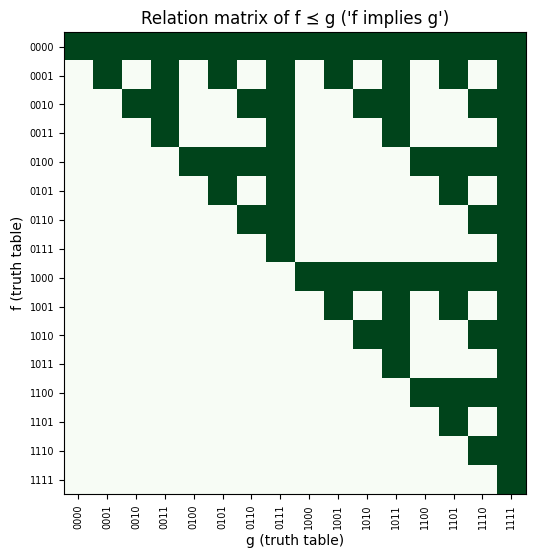

In [10]:
funcs2 = list(product((0, 1), repeat=4))         # all 16 truth tables of 2-input functions
def implies(f, g):
    return all(fx <= gx for fx, gx in zip(f, g))

matrix = [[int(implies(f, g)) for g in funcs2] for f in funcs2]
refl = all(implies(f, f) for f in funcs2)
antisym = all(f == g for f in funcs2 for g in funcs2 if implies(f, g) and implies(g, f))
trans = all(implies(f, h) for f in funcs2 for g in funcs2 for h in funcs2 if implies(f, g) and implies(g, h))
incomparable = next((f, g) for f in funcs2 for g in funcs2 if not implies(f, g) and not implies(g, f))
print(f"Reflexive: {refl},  antisymmetric: {antisym},  transitive: {trans}  ->  partial order")
print(f"Not total: the functions with truth tables {incomparable[0]} and {incomparable[1]} cannot be compared")

plt.figure(figsize=(6, 6))
plt.imshow(matrix, cmap="Greens")
labels = ["".join(map(str, f)) for f in funcs2]
plt.xticks(range(16), labels, rotation=90, fontsize=7)
plt.yticks(range(16), labels, fontsize=7)
plt.xlabel("g (truth table)")
plt.ylabel("f (truth table)")
plt.title("Relation matrix of f ⪯ g ('f implies g')")
plt.grid(False)
plt.show()

## 5. Designing and minimising circuits

### 5.1 From truth table to circuit
Any truth table can be turned into a circuit. Take one AND term (**minterm**) for each row with output 1, then OR the terms together. This is the **canonical sum of products**. It is correct but usually wasteful.

### 5.2 Quine–McCluskey minimisation
The Quine–McCluskey method works on **sets of implicants**, written as strings such as `1-0`, where `-` means "either value":
1. Repeatedly merge two implicants that differ in exactly one bit (`110` and `100` → `1-0`).
2. Implicants that can't be merged further are **prime implicants**.
3. Choose the smallest **combination** of prime implicants whose union covers every minterm. We search combinations of size 1, 2, 3, … in turn.

In [11]:
def to_bits(m, n):
    return format(m, f"0{n}b")

def combine(p, q):
    diff = [i for i in range(len(p)) if p[i] != q[i]]
    if len(diff) == 1 and "-" not in (p[diff[0]], q[diff[0]]):
        i = diff[0]
        return p[:i] + "-" + p[i + 1:]
    return None

def prime_implicants(minterms, n):
    current = {to_bits(m, n) for m in minterms}
    primes = set()
    while current:
        merged, used = set(), set()
        cur = sorted(current)
        for i in range(len(cur)):
            for j in range(i + 1, len(cur)):
                c = combine(cur[i], cur[j])
                if c:
                    merged.add(c)
                    used.update({cur[i], cur[j]})
        primes |= current - used
        current = merged
    return primes

def covers(implicant, m, n):
    return all(c == "-" or c == b for c, b in zip(implicant, to_bits(m, n)))

def literals(implicant):
    return sum(c != "-" for c in implicant)

def minimal_cover(minterms, n):
    primes = sorted(prime_implicants(minterms, n))
    for k in range(1, len(primes) + 1):
        candidates = [set(c) for c in combinations(primes, k)
                      if all(any(covers(p, m, n) for p in c) for m in minterms)]
        if candidates:
            return primes, min(candidates, key=lambda c: sum(literals(p) for p in c))
    return primes, set()

def pretty(cover, names):
    terms = ["".join(v if c == "1" else v + "'" for c, v in zip(imp, names) if c != "-") or "1"
             for imp in sorted(cover)]
    return " + ".join(terms) if terms else "0"

def to_python(cover, names):
    terms = ["(" + " and ".join(v if c == "1" else f"not {v}" for c, v in zip(imp, names) if c != "-") + ")"
             if literals(imp) else "True" for imp in sorted(cover)]
    return " or ".join(terms) if terms else "False"

def minterms_of(f, n):
    return [i for i, bits in enumerate(all_inputs(n)) if f(*bits)]

In [12]:
def design(name, spec, names):
    n = len(names)
    mins = minterms_of(spec, n)
    canonical = {to_bits(m, n) for m in mins}
    primes, cover = minimal_cover(mins, n)
    simplified = formula(to_python(cover, names), names)
    same = truth_table(simplified, n) == truth_table(spec, n)
    print(f"=== {name} ===")
    print(f"Minterms: {mins}")
    print(f"Canonical sum of products: {pretty(canonical, names)}   ({sum(literals(p) for p in canonical)} literals)")
    print(f"Prime implicants: {sorted(primes)}")
    print(f"Minimal circuit:  {pretty(cover, names)}   ({sum(literals(p) for p in cover)} literals)")
    print(f"Equivalent to the specification (checked on all {2**n} rows): {same}\n")
    return cover

majority_spec = lambda a, b, c: a + b + c >= 2
maj_cover = design("Majority voter", majority_spec, NAMES3)
sum_cover = design("Full adder SUM output", lambda a, b, c: full_adder(a, b, c)[0], NAMES3)
carry_cover = design("Full adder CARRY output", lambda a, b, c: full_adder(a, b, c)[1], NAMES3)
print("Observation: the full adder's carry-out IS the majority function.")
print("The SUM output cannot be reduced at all: no two minterms are adjacent, so the XOR form a ⊕ b ⊕ c is used instead.")

print_truth_table(NAMES3, {"MAJ": majority_spec,
                           "SUM": lambda a, b, c: full_adder(a, b, c)[0],
                           "CARRY": lambda a, b, c: full_adder(a, b, c)[1]})

=== Majority voter ===
Minterms: [3, 5, 6, 7]
Canonical sum of products: a'bc + ab'c + abc' + abc   (12 literals)
Prime implicants: ['-11', '1-1', '11-']
Minimal circuit:  bc + ac + ab   (6 literals)
Equivalent to the specification (checked on all 8 rows): True

=== Full adder SUM output ===
Minterms: [1, 2, 4, 7]
Canonical sum of products: a'b'c + a'bc' + ab'c' + abc   (12 literals)
Prime implicants: ['001', '010', '100', '111']
Minimal circuit:  a'b'c + a'bc' + ab'c' + abc   (12 literals)
Equivalent to the specification (checked on all 8 rows): True

=== Full adder CARRY output ===
Minterms: [3, 5, 6, 7]
Canonical sum of products: a'bc + ab'c + abc' + abc   (12 literals)
Prime implicants: ['-11', '1-1', '11-']
Minimal circuit:  bc + ac + ab   (6 literals)
Equivalent to the specification (checked on all 8 rows): True

Observation: the full adder's carry-out IS the majority function.
The SUM output cannot be reduced at all: no two minterms are adjacent, so the XOR form a ⊕ b ⊕ c is use

In [13]:
# A larger example: a 4-input function (a BCD digit detector: output 1 for the valid decimal digits 0–9
# that are prime, i.e. 2, 3, 5, 7), with the unused codes 10–15 treated as 'never 1'
NAMES4 = ["a", "b", "c", "d"]
prime_digit = lambda a, b, c, d: (8 * a + 4 * b + 2 * c + d) in {2, 3, 5, 7}
design("Prime-digit detector (4 inputs)", prime_digit, NAMES4)

=== Prime-digit detector (4 inputs) ===
Minterms: [2, 3, 5, 7]
Canonical sum of products: a'b'cd' + a'b'cd + a'bc'd + a'bcd   (16 literals)
Prime implicants: ['0-11', '001-', '01-1']
Minimal circuit:  a'b'c + a'bd   (6 literals)
Equivalent to the specification (checked on all 16 rows): True



{'001-', '01-1'}

## 6. Counting: how many inputs, functions and designs?

### 6.1 The product rule and the explosion of possibilities
* An $n$-input circuit has $2 \cdot 2 \cdots 2 = 2^n$ input rows (**product rule**).
* Each row can output 0 or 1, so there are $2^{2^n}$ different Boolean functions.

In [14]:
print(" n   input rows 2^n    Boolean functions 2^(2^n)")
for n in range(1, 7):
    print(f"{n:2d}   {2**n:12d}     {2**(2**n):.4e}" if n > 4 else f"{n:2d}   {2**n:12d}     {2**(2**n):,}")

print("\nExhaustive testing of a 64-bit adder needs 2^128 input pairs:")
seconds = 2 ** 128 / 1e9
print(f"  at 10^9 tests per second that is {seconds / (3600*24*365):.3e} years -> a PROOF is needed instead (Section 9)")

 n   input rows 2^n    Boolean functions 2^(2^n)
 1              2     4
 2              4     16
 3              8     256
 4             16     65,536
 5             32     4.2950e+09
 6             64     1.8447e+19

Exhaustive testing of a 64-bit adder needs 2^128 input pairs:
  at 10^9 tests per second that is 1.079e+22 years -> a PROOF is needed instead (Section 9)


### 6.2 Counting special classes of functions, checked by brute force
For $n = 3$, we list all 256 functions and count those with special properties. Then we compare each count with a formula.

| Class | Formula | Reasoning |
|---|---|---|
| exactly $k$ ones in the truth table | $\binom{2^n}{k}$ | choose which $k$ of the $2^n$ rows output 1 (combinations) |
| balanced (half ones) | $\binom{2^n}{2^{n-1}}$ | special case of the above |
| symmetric (depends only on the number of 1 inputs) | $2^{n+1}$ | choose an output for each weight $0,1,\dots,n$ |
| self-dual ($f(\bar x) = \overline{f(x)}$) | $2^{2^{n-1}}$ | inputs pair up with their complements, and one choice per pair |
| monotone (never 1 → 0 when an input rises) | no simple formula (Dedekind numbers) | brute force only |

In [15]:
n = 3
inputs3 = all_inputs(n)
idx = {x: i for i, x in enumerate(inputs3)}
all_funcs = list(product((0, 1), repeat=2 ** n))

def is_symmetric(f):
    return all(f[idx[x]] == f[idx[y]] for x in inputs3 for y in inputs3 if sum(x) == sum(y))

def is_self_dual(f):
    return all(f[idx[tuple(1 - b for b in x)]] == 1 - f[idx[x]] for x in inputs3)

def is_monotone(f, inputs=inputs3, index=idx):
    return all(f[index[x]] <= f[index[y]] for x in inputs for y in inputs if all(a <= b for a, b in zip(x, y)))

print(f"Total functions: {len(all_funcs)} (formula 2^(2^n) = {2**2**n})")
for k in [0, 1, 3, 4]:
    print(f"Exactly {k} ones: {sum(sum(f) == k for f in all_funcs):3d}   (formula C(8,{k}) = {comb(8, k)})")
print(f"Symmetric:  {sum(map(is_symmetric, all_funcs)):3d}   (formula 2^(n+1) = {2**(n+1)})")
print(f"Self-dual:  {sum(map(is_self_dual, all_funcs)):3d}   (formula 2^(2^(n-1)) = {2**2**(n-1)})")
print(f"Monotone:   {sum(map(is_monotone, all_funcs)):3d}   (Dedekind number for n = 3 is 20)")
print(f"\nThe majority function is symmetric: {is_symmetric(truth_table(majority_spec, 3))}, "
      f"self-dual: {is_self_dual(truth_table(majority_spec, 3))}, monotone: {is_monotone(truth_table(majority_spec, 3))}")

Total functions: 256 (formula 2^(2^n) = 256)
Exactly 0 ones:   1   (formula C(8,0) = 1)
Exactly 1 ones:   8   (formula C(8,1) = 8)
Exactly 3 ones:  56   (formula C(8,3) = 56)
Exactly 4 ones:  70   (formula C(8,4) = 70)
Symmetric:   16   (formula 2^(n+1) = 16)
Self-dual:   16   (formula 2^(2^(n-1)) = 16)
Monotone:    20   (Dedekind number for n = 3 is 20)

The majority function is symmetric: True, self-dual: True, monotone: True


### 6.3 Permutations and combinations in test and assembly
* **Permutations** count *ordered* arrangements: $P(n,r) = \dfrac{n!}{(n-r)!}$.
* **Combinations** count *unordered* selections: $\binom{n}{r} = \dfrac{n!}{r!\,(n-r)!}$.

In [16]:
print(f"Ways to connect 4 sensor wires to the 4 input pins of a chip:    4! = {factorial(4)}")
print(f"Ordered test sequences of 3 different inputs (out of 8):          P(8,3) = {perm(8, 3)}")
print(f"Unordered test sets of 3 different inputs (out of 8):             C(8,3) = {comb(8, 3)}")
print(f"Relation: P(8,3) = C(8,3) × 3!  ->  {perm(8, 3)} = {comb(8, 3)} × {factorial(3)}")
print(f"Inputs of an 8-bit bus with exactly 3 lines high:                 C(8,3) = {comb(8, 3)}")

# Brute-force check with itertools
print("\nBrute-force check:", len(list(permutations(range(8), 3))) == perm(8, 3),
      len(list(combinations(range(8), 3))) == comb(8, 3))

# Sum rule: test inputs with at most one line high on an 8-bit bus
print(f"Sum rule: inputs with 0 or 1 lines high = C(8,0) + C(8,1) = {comb(8, 0) + comb(8, 1)}")

Ways to connect 4 sensor wires to the 4 input pins of a chip:    4! = 24
Ordered test sequences of 3 different inputs (out of 8):          P(8,3) = 336
Unordered test sets of 3 different inputs (out of 8):             C(8,3) = 56
Relation: P(8,3) = C(8,3) × 3!  ->  336 = 56 × 6
Inputs of an 8-bit bus with exactly 3 lines high:                 C(8,3) = 56

Brute-force check: True True
Sum rule: inputs with 0 or 1 lines high = C(8,0) + C(8,1) = 9


### 6.4 The pigeonhole principle: unavoidable collisions
If $N$ objects go into $k$ boxes, some box holds at least $\lceil N/k \rceil$ objects. A 4-bit checksum of an 8-bit word maps 256 inputs to 16 values, so some checksum value is shared by at least 16 different words. No checksum design can avoid this.

In [17]:
def checksum4(x):                      # x is an 8-bit tuple; checksum = XOR of the two 4-bit halves
    return tuple(a ^ b for a, b in zip(x[:4], x[4:]))

buckets = {}
for x in all_inputs(8):
    buckets.setdefault(checksum4(x), []).append(x)
print(f"256 words into 16 checksum values: largest group = {max(map(len, buckets.values()))}, "
      f"pigeonhole guarantee = ⌈256/16⌉ = {ceil(256 / 16)}")

256 words into 16 checksum values: largest group = 16, pigeonhole guarantee = ⌈256/16⌉ = 16


## 7. Recursive circuits

Large digital circuits are built **recursively** from smaller copies of themselves. Each recursive definition needs a **base case** and a **recursive step**.

### 7.1 Gray code
In a Gray code, consecutive values differ in exactly one bit. Position encoders use it so that a reading taken mid-transition is never badly wrong. Recursive definition:
* **Base case:** $G_0 = [\,\varepsilon\,]$ (the list containing the empty string).
* **Recursive step:** $G_n = 0G_{n-1}$ followed by $1\,\text{reverse}(G_{n-1})$.

In [18]:
def gray(n):
    if n == 0:
        return [""]
    prev = gray(n - 1)
    return ["0" + c for c in prev] + ["1" + c for c in reversed(prev)]

def hamming(u, v):
    return sum(x != y for x, y in zip(u, v))

for n in range(1, 5):
    g = gray(n)
    one_bit = all(hamming(g[i], g[(i + 1) % len(g)]) == 1 for i in range(len(g)))
    print(f"G_{n} = {g}" if n <= 3 else f"G_4 has {len(g)} codes", f"  -> neighbours differ in 1 bit (cyclic): {one_bit}")

# The same code from the bitwise formula g = b XOR (b >> 1)
print("Matches g = b ⊕ (b >> 1):", all(int(c, 2) == b ^ (b >> 1) for b, c in enumerate(gray(6))))

G_1 = ['0', '1']   -> neighbours differ in 1 bit (cyclic): True
G_2 = ['00', '01', '11', '10']   -> neighbours differ in 1 bit (cyclic): True
G_3 = ['000', '001', '011', '010', '110', '111', '101', '100']   -> neighbours differ in 1 bit (cyclic): True
G_4 has 16 codes   -> neighbours differ in 1 bit (cyclic): True
Matches g = b ⊕ (b >> 1): True


### 7.2 A recursive ripple-carry adder
An $n$-bit adder is a full adder for the lowest bit plus an $(n-1)$-bit adder for the rest, which receives the carry.
* **Base case:** with no bits left, the result is just the carry.
* **Recursive step:** add bit 0 with a full adder and pass its carry to the adder for the remaining bits.

Bits are stored least-significant first.

In [19]:
def to_bit_list(x, n):
    return [(x >> i) & 1 for i in range(n)]          # least-significant bit first

def from_bit_list(bits):
    return sum(b << i for i, b in enumerate(bits))

def ripple_add(a_bits, b_bits, carry=0):
    if not a_bits:                                   # base case
        return [carry]
    s, c = full_adder(a_bits[0], b_bits[0], carry)   # recursive step
    return [s] + ripple_add(a_bits[1:], b_bits[1:], c)

a, b = 11, 6
result = ripple_add(to_bit_list(a, 4), to_bit_list(b, 4))
print(f"{a} + {b}: bits (LSB first) {result} -> {from_bit_list(result)}")

11 + 6: bits (LSB first) [1, 0, 0, 0, 1] -> 17


### 7.3 A recursive multiplexer tree
A $2^n$-to-1 multiplexer selects one of $2^n$ data lines. It can be built from two $2^{n-1}$-to-1 multiplexers and one 2-to-1 multiplexer. We count the 2-to-1 multiplexers used as the recursion runs.

In [20]:
def mux2(sel, d0, d1):
    return d1 if sel else d0

def mux_tree(select_bits, data):
    # Returns (selected value, number of 2-to-1 multiplexers used); select_bits is MSB first
    if len(data) == 1:
        return data[0], 0
    half = len(data) // 2
    low, used_low = mux_tree(select_bits[1:], data[:half])
    high, used_high = mux_tree(select_bits[1:], data[half:])
    return mux2(select_bits[0], low, high), used_low + used_high + 1

for n in range(1, 6):
    data = [f"D{i}" for i in range(2 ** n)]
    correct = all(mux_tree(list(sel), data)[0] == data[i] for i, sel in enumerate(all_inputs(n)))
    print(f"n = {n}: {2**n:2d}-to-1 multiplexer uses {mux_tree([0]*n, data)[1]:2d} two-input muxes, "
          f"always selects the right line: {correct}")

n = 1:  2-to-1 multiplexer uses  1 two-input muxes, always selects the right line: True
n = 2:  4-to-1 multiplexer uses  3 two-input muxes, always selects the right line: True
n = 3:  8-to-1 multiplexer uses  7 two-input muxes, always selects the right line: True
n = 4: 16-to-1 multiplexer uses 15 two-input muxes, always selects the right line: True
n = 5: 32-to-1 multiplexer uses 31 two-input muxes, always selects the right line: True


## 8. Cost and delay: recurrence relations

### 8.1 Multiplexer cost
From the recursive construction, the number of 2-to-1 multiplexers satisfies
$$M(n) = 2M(n-1) + 1, \qquad M(0) = 0 .$$
**Unrolling:** $M(n) = 2^k M(n-k) + (2^{k-1} + \dots + 2 + 1)$. With $k = n$ this gives $M(n) = 2^n - 1$.

### 8.2 Adder delay: ripple vs divide and conquer
* **Ripple carry:** each stage waits for the previous carry, so $D(n) = D(n-1) + 2$ with $D(1) = 2$ gate delays. This gives $D(n) = 2n$, which is *linear*.
* **Carry-lookahead (tree):** the carries are combined in a balanced tree, so $T(n) = T(n/2) + 2$ with $T(1)=2$. This gives $T(n) = 2(\log_2 n + 1)$, which is *logarithmic*.

 n   M(n) recurrence   2^n - 1
 0                0         0
 1                1         1
 2                3         3
 3                7         7
 4               15        15
 5               31        31
 6               63        63
 7              127       127
 8              255       255

Word size   ripple delay D(n)=2n   lookahead delay T(n)=2(log2 n + 1)
        1                     2                                   2   check: True
        2                     4                                   4   check: True
        4                     8                                   6   check: True
        8                    16                                   8   check: True
       16                    32                                  10   check: True
       32                    64                                  12   check: True
       64                   128                                  14   check: True


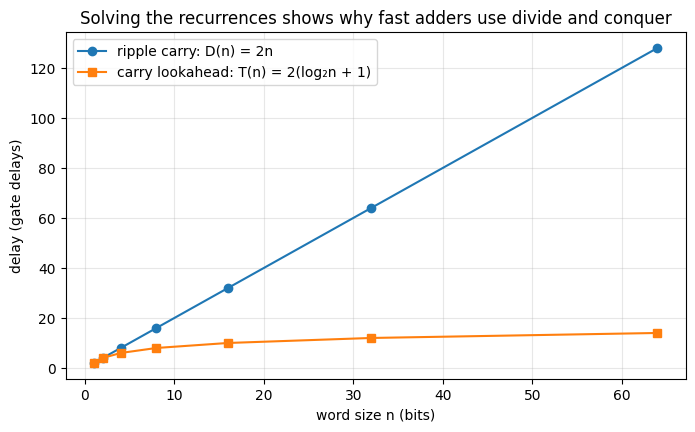

In [21]:
def M(n):
    return 0 if n == 0 else 2 * M(n - 1) + 1

def D(n):
    return 2 if n == 1 else D(n - 1) + 2

def T(n):
    return 2 if n == 1 else T(n // 2) + 2

print(" n   M(n) recurrence   2^n - 1")
for n in range(0, 9):
    print(f"{n:2d}   {M(n):14d}   {2**n - 1:7d}")

sizes = [1, 2, 4, 8, 16, 32, 64]
print("\nWord size   ripple delay D(n)=2n   lookahead delay T(n)=2(log2 n + 1)")
for n in sizes:
    print(f"{n:9d}   {D(n):19d}   {T(n):33d}   check: {D(n) == 2*n and T(n) == 2*(int(log2(n)) + 1)}")

plt.plot(sizes, [D(n) for n in sizes], "o-", label="ripple carry: D(n) = 2n")
plt.plot(sizes, [T(n) for n in sizes], "s-", label="carry lookahead: T(n) = 2(log₂n + 1)")
plt.xlabel("word size n (bits)")
plt.ylabel("delay (gate delays)")
plt.title("Solving the recurrences shows why fast adders use divide and conquer")
plt.legend()
plt.show()

### 8.3 A second-order recurrence: crosstalk-avoiding bus codes
On a fast bus, two **adjacent** wires carrying 1 at the same time can interfere (crosstalk). How many $n$-bit words have **no two consecutive 1s**?

A valid word either ends in 0 (any valid $(n-1)$-bit word, then 0) or ends in 01 (any valid $(n-2)$-bit word, then 01):
$$a_n = a_{n-1} + a_{n-2}, \qquad a_1 = 2,\ a_2 = 3 .$$
**Characteristic equation:** $r^2 = r + 1$, so $r = \varphi = \frac{1+\sqrt5}{2}$ or $r = \psi = \frac{1-\sqrt5}{2}$. The closed form is $a_n = c_1\varphi^n + c_2\psi^n$, where the constants come from the initial conditions.

In [22]:
def valid(word):
    return all(not (word[i] and word[i + 1]) for i in range(len(word) - 1))

def a_rec(n):
    if n == 1: return 2
    if n == 2: return 3
    return a_rec(n - 1) + a_rec(n - 2)

phi, psi = (1 + 5 ** 0.5) / 2, (1 - 5 ** 0.5) / 2
# Solve c1·φ + c2·ψ = 2 and c1·φ² + c2·ψ² = 3 for c1, c2
det = phi * psi**2 - psi * phi**2
c1 = (2 * psi**2 - 3 * psi) / det
c2 = (3 * phi - 2 * phi**2) / det
closed = lambda n: c1 * phi**n + c2 * psi**n

print(f"Closed form: a_n = {c1:.4f}·φⁿ + {c2:.4f}·ψⁿ")
print(" n   brute force   recurrence   closed form")
for n in range(1, 13):
    brute = sum(valid(w) for w in all_inputs(n))
    print(f"{n:2d}   {brute:11d}   {a_rec(n):10d}   {closed(n):11.4f}")

Closed form: a_n = 1.1708·φⁿ + -0.1708·ψⁿ
 n   brute force   recurrence   closed form
 1             2            2        2.0000
 2             3            3        3.0000
 3             5            5        5.0000
 4             8            8        8.0000
 5            13           13       13.0000
 6            21           21       21.0000
 7            34           34       34.0000
 8            55           55       55.0000
 9            89           89       89.0000
10           144          144      144.0000
11           233          233      233.0000
12           377          377      377.0000


### 8.4 The cost of naive recursion, and memoisation
Computing $a_n$ straight from the recurrence repeats the same sub-problems again and again, so the number of calls itself grows like a Fibonacci sequence. **Memoisation** stores each answer once, which makes the work linear.

In [23]:
calls = {"naive": 0}
def a_naive(n):
    calls["naive"] += 1
    return 2 if n == 1 else 3 if n == 2 else a_naive(n - 1) + a_naive(n - 2)

@lru_cache(maxsize=None)
def a_memo(n):
    return 2 if n == 1 else 3 if n == 2 else a_memo(n - 1) + a_memo(n - 2)

print(" n   value   naive calls   memoised distinct calls")
for n in [5, 10, 15, 20, 25]:
    calls["naive"] = 0
    a_memo.cache_clear()
    value = a_naive(n)
    a_memo(n)
    print(f"{n:2d}   {value:6d}   {calls['naive']:11d}   {a_memo.cache_info().currsize:23d}")

 n   value   naive calls   memoised distinct calls
 5       13             9                         5
10      144           109                        10
15     1597          1219                        15
20    17711         13529                        20
25   196418        150049                        25


## 9. Proving circuits correct

Testing can only cover a few word sizes, and Section 6 showed that exhaustive testing of a 64-bit adder is impossible. **Proofs** cover every case.

### 9.1 Proof by mathematical induction: the ripple-carry adder is correct
**Claim.** For every $n \ge 0$, all $n$-bit numbers $a, b$ and every carry-in $c \in \{0,1\}$, `ripple_add` returns the binary form of $a + b + c$.

**Base case ($n=0$).** Then $a = b = 0$ and the function returns $[c]$, whose value is $c = a + b + c$. ✓

**Inductive step.** Assume the claim holds for $n-1$ bits (the **inductive hypothesis**). Write $a = a_0 + 2a'$ and $b = b_0 + 2b'$, where $a_0, b_0$ are the lowest bits and $a', b'$ are $(n-1)$-bit numbers.
1. The full adder gives $s$ and $c'$ with $a_0 + b_0 + c = s + 2c'$. This holds by checking all 8 rows of its truth table, which is a proof by exhaustion.
2. By the inductive hypothesis, the recursive call returns the value $a' + b' + c'$.
3. The result is $s$ followed by those bits, so its value is
$$s + 2(a' + b' + c') = (s + 2c') + 2a' + 2b' = a_0 + b_0 + c + 2a' + 2b' = a + b + c. \;✓$$

By the principle of mathematical induction, the adder is correct for **every** word size. $\blacksquare$

In [24]:
# Step 1 of the proof (the full-adder identity), proved by exhaustion
print("Full adder identity a0 + b0 + c = s + 2c' holds on all 8 rows:",
      all(a0 + b0 + c == s + 2 * cp for a0, b0, c in all_inputs(3) for s, cp in [full_adder(a0, b0, c)]))

# Supporting evidence (not a proof): exhaustive tests for small word sizes
for n in range(1, 9):
    ok = all(from_bit_list(ripple_add(to_bit_list(x, n), to_bit_list(y, n), c)) == x + y + c
             for x in range(2 ** n) for y in range(2 ** n) for c in (0, 1))
    print(f"  n = {n}: all {2 * 4**n:6d} cases correct: {ok}")

Full adder identity a0 + b0 + c = s + 2c' holds on all 8 rows: True
  n = 1: all      8 cases correct: True
  n = 2: all     32 cases correct: True
  n = 3: all    128 cases correct: True
  n = 4: all    512 cases correct: True
  n = 5: all   2048 cases correct: True
  n = 6: all   8192 cases correct: True
  n = 7: all  32768 cases correct: True
  n = 8: all 131072 cases correct: True


### 9.2 More inductive proofs
**Claim A: there are $2^n$ binary strings of length $n$.** For the base case $n=0$, there is 1 string (the empty one), and $2^0 = 1$. For the step, each string of length $n$ is a string of length $n-1$ followed by 0 or 1, giving $2 \cdot 2^{n-1} = 2^n$. $\blacksquare$

**Claim B: $M(n) = 2^n - 1$.** For the base case, $M(0) = 0 = 2^0 - 1$. For the step, $M(n) = 2M(n-1)+1 = 2(2^{n-1}-1)+1 = 2^n - 1$. $\blacksquare$

**Claim C: consecutive codes in $G_n$ differ in exactly one bit.** For the base case, $G_1 = [0, 1]$. For the step, inside each half the codes are those of $G_{n-1}$ with the same prefix added, so the claim holds by the hypothesis. At the junction, the last code of the first half is $0w$ and the first code of the second half is $1w$, because of the reversal. These differ only in the first bit. $\blacksquare$

In [25]:
print("Claim A:", all(len(all_inputs(n)) == 2 ** n for n in range(0, 13)))
print("Claim B:", all(M(n) == 2 ** n - 1 for n in range(0, 20)))
print("Claim C:", all(hamming(g[i], g[i + 1]) == 1 for n in range(1, 11) for g in [gray(n)] for i in range(len(g) - 1)))

Claim A: True
Claim B: True
Claim C: True


### 9.3 Proof by contradiction: XOR cannot be built from AND and OR alone
**Claim.** No circuit made only of AND and OR gates, with inputs $a$ and $b$, computes $a \oplus b$.

**Proof.** Suppose, for contradiction, that such a circuit exists.
* **Lemma (by induction on the circuit's structure):** every AND/OR circuit is **monotone**. Changing an input from 0 to 1 can never change the output from 1 to 0. The inputs themselves are monotone, and AND and OR of monotone functions are monotone.
* XOR is **not** monotone: $0 \oplus 1 = 1$, but raising $a$ gives $1 \oplus 1 = 0$.
* So the circuit would be both monotone and not monotone, which is a **contradiction**. Therefore no such circuit exists. $\blacksquare$

We confirm this computationally. We build the **closure** of $\{a, b\}$ under AND and OR, meaning every function such circuits can ever produce, and check that XOR is not in it.

In [26]:
def closure(start, ops):
    funcs = set(start)
    while True:
        new = {op(f, g) for op in ops for f in funcs for g in funcs} - funcs
        if not new:
            return funcs
        funcs |= new

AND = lambda f, g: tuple(x & y for x, y in zip(f, g))
OR = lambda f, g: tuple(x | y for x, y in zip(f, g))
NAND = lambda f, g: tuple(1 - (x & y) for x, y in zip(f, g))

a_tt = truth_table(lambda a, b: a, 2)
b_tt = truth_table(lambda a, b: b, 2)
xor_tt = truth_table(lambda a, b: a ^ b, 2)
inputs2, idx2 = all_inputs(2), {x: i for i, x in enumerate(all_inputs(2))}

reachable = closure({a_tt, b_tt}, [AND, OR])
print("Functions reachable with AND/OR only:", sorted(reachable))
print("All of them monotone:", all(is_monotone(f, inputs2, idx2) for f in reachable))
print("XOR is monotone:", is_monotone(xor_tt, inputs2, idx2))
print("XOR reachable with AND/OR:", xor_tt in reachable, " -> consistent with the proof")

Functions reachable with AND/OR only: [(0, 0, 0, 1), (0, 0, 1, 1), (0, 1, 0, 1), (0, 1, 1, 1)]
All of them monotone: True
XOR is monotone: False
XOR reachable with AND/OR: False  -> consistent with the proof


### 9.4 Constructive proof: NAND alone can build every circuit
**Claim.** Every Boolean function can be built from NAND gates only. NAND is **functionally complete**.

**Proof (by construction).**
* $\lnot a = \text{NAND}(a, a)$
* $a \land b = \lnot\,\text{NAND}(a,b)$
* $a \lor b = \text{NAND}(\lnot a, \lnot b)$, by De Morgan's law

Since every function has a sum-of-products form (Section 5), and NOT, AND and OR can all be built from NAND, every function can be built from NAND. $\blacksquare$

The computation below confirms that the closure of $\{a, b\}$ under NAND contains **all 16** two-input functions.

In [27]:
nand_closure = closure({a_tt, b_tt}, [NAND])
print(f"Functions reachable with NAND only: {len(nand_closure)} of {2**2**2}")
NOT_n = lambda f: NAND(f, f)
print("NOT a  = NAND(a, a)              :", NOT_n(a_tt) == truth_table(lambda a, b: 1 - a, 2))
print("a AND b = NOT NAND(a, b)          :", NOT_n(NAND(a_tt, b_tt)) == truth_table(lambda a, b: a & b, 2))
print("a OR b = NAND(NOT a, NOT b)       :", NAND(NOT_n(a_tt), NOT_n(b_tt)) == truth_table(lambda a, b: a | b, 2))
print("XOR with 4 NANDs                  :",
      NAND(NAND(a_tt, NAND(a_tt, b_tt)), NAND(b_tt, NAND(a_tt, b_tt))) == xor_tt)

Functions reachable with NAND only: 16 of 16
NOT a  = NAND(a, a)              : True
a AND b = NOT NAND(a, b)          : True
a OR b = NAND(NOT a, NOT b)       : True
XOR with 4 NANDs                  : True


### 9.5 Proof by contradiction: no lossless 8-bit → 7-bit encoder
**Claim.** No circuit can encode every 8-bit word into 7 bits in a way that can always be decoded.

**Proof.** Suppose such an encoder $E$ exists. To be decodable it must be **injective**. But $E$ maps a set of $2^8 = 256$ words into a set of $2^7 = 128$ codes. By the pigeonhole principle, two words share a code, so $E$ is not injective. This is a contradiction. $\blacksquare$

This is why compression can only shorten *some* inputs.

## 10. Codes and parts: generating functions

A **generating function** stores a whole counting sequence $a_0, a_1, a_2, \dots$ as the coefficients of a power series $A(x) = \sum a_n x^n$. Multiplying generating functions combines independent choices. We represent series as Python lists of coefficients.

In [28]:
def poly_mul(p, q, max_deg=None):
    out = [0] * (len(p) + len(q) - 1)
    for i, pi in enumerate(p):
        for j, qj in enumerate(q):
            out[i + j] += pi * qj
    return out[: max_deg + 1] if max_deg is not None else out

def series_div(p, q, n_terms):
    # Coefficients of P(x)/Q(x) as a power series (q[0] must be non-zero)
    c = []
    for n in range(n_terms):
        pn = p[n] if n < len(p) else 0
        s = sum(q[k] * c[n - k] for k in range(1, min(n, len(q) - 1) + 1))
        c.append((pn - s) / q[0])
    return [round(v) for v in c]

### 10.1 Binomial generating function: inputs of each weight
Each bit contributes either weight 0 or weight 1, i.e. a factor $(1 + x)$. So
$$(1+x)^n = \sum_{k} \binom{n}{k} x^k ,$$
and the coefficient of $x^k$ counts $n$-bit inputs with exactly $k$ ones. Quine–McCluskey groups minterms by exactly this weight.

**Parity codes.** Substituting $x = 1$ and $x = -1$ gives
$$\#\{\text{even-weight words}\} = \frac{(1+1)^n + (1-1)^n}{2} = 2^{n-1}.$$
So exactly half of all words have even parity. The parity generator's job is to make every transmitted word one of these.

In [29]:
gf = [1]
for _ in range(8):
    gf = poly_mul(gf, [1, 1])
print("(1+x)^8 coefficients :", gf)
print("Binomial C(8,k)      :", [comb(8, k) for k in range(9)])
print("Brute-force weights  :", [sum(sum(x) == k for x in all_inputs(8)) for k in range(9)])

even = (sum(gf) + sum(c * (-1) ** k for k, c in enumerate(gf))) // 2
print(f"\nEven-weight 8-bit words: (f(1) + f(-1)) / 2 = {even} = 2^7")

def parity_bit(word):                      # XOR chain: makes the total number of 1s even
    p = 0
    for b in word:
        p ^= b
    return p

codewords = [x + (parity_bit(x),) for x in all_inputs(7)]
print(f"All {len(codewords)} codewords (7 data bits + parity) have even weight:",
      all(sum(w) % 2 == 0 for w in codewords))
flipped = codewords[37][:3] + (1 - codewords[37][3],) + codewords[37][4:]
print("A single flipped bit is detected (odd weight):", sum(flipped) % 2 == 1)

(1+x)^8 coefficients : [1, 8, 28, 56, 70, 56, 28, 8, 1]
Binomial C(8,k)      : [1, 8, 28, 56, 70, 56, 28, 8, 1]
Brute-force weights  : [1, 8, 28, 56, 70, 56, 28, 8, 1]

Even-weight 8-bit words: (f(1) + f(-1)) / 2 = 128 = 2^7
All 128 codewords (7 data bits + parity) have even weight: True
A single flipped bit is detected (odd weight): True


### 10.2 A rational generating function: crosstalk-avoiding codes
From the recurrence in Section 8.3, with $a_0 = 1$ and $a_1 = 2$, the generating function $A(x) = \sum a_n x^n$ satisfies $(1 - x - x^2)A(x) = 1 + x$. So
$$A(x) = \frac{1 + x}{1 - x - x^2}.$$
Expanding this fraction as a power series reproduces the counts found by brute force.

In [30]:
coeffs = series_div([1, 1], [1, -1, -1], 13)
brute = [1] + [sum(valid(w) for w in all_inputs(n)) for n in range(1, 13)]
print("Series of (1+x)/(1-x-x²):", coeffs)
print("Brute force counts      :", brute)
print("Match:", coeffs == brute)

Series of (1+x)/(1-x-x²): [1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]
Brute force counts      : [1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]
Match: True


### 10.3 Product generating functions: buying logic chips
A technician needs exactly $N$ gates and can buy three chip types:

| Chip | Contents | Gates per chip |
|---|---|---|
| 7410 | three 3-input NAND gates | 3 |
| 7400 | four 2-input NAND gates | 4 |
| 7404 | six inverters | 6 |

How many different chip combinations give exactly $N$ gates?
* **Unlimited stock:** each chip type contributes $1 + x^s + x^{2s} + \dots = \dfrac{1}{1-x^s}$, so
$$G(x) = \frac{1}{(1-x^3)(1-x^4)(1-x^6)} .$$
* **At most 2 of each chip:** each type contributes the polynomial $1 + x^s + x^{2s}$.

Unlimited stock, ways for N = 0..30: [1, 0, 0, 1, 1, 0, 2, 1, 1, 2, 2, 1, 4, 2, 2, 4, 4, 2, 6, 4, 4, 6, 6, 4, 9, 6, 6, 9, 9, 6, 12]
Matches brute force: True
At most 2 of each,  ways for N = 0..30: [1, 0, 0, 1, 1, 0, 2, 1, 1, 1, 2, 1, 2, 1, 2, 1, 2, 1, 1, 1, 2, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0]
Matches brute force: True

Example: exactly 12 gates can be bought in 4 ways (unlimited) or 2 ways (≤ 2 each)


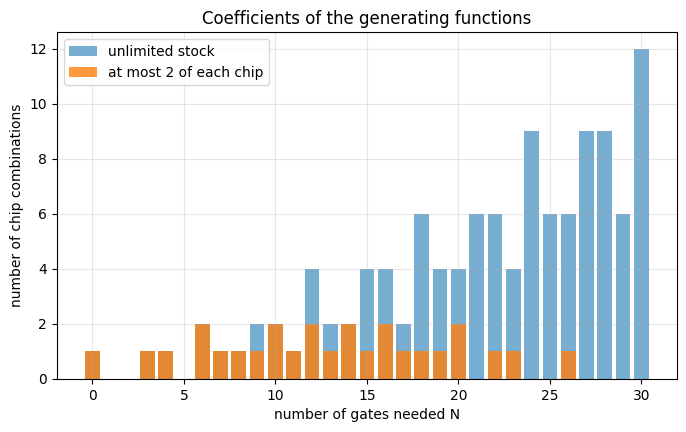

In [31]:
N_MAX = 30
denominator = poly_mul(poly_mul([1, 0, 0, -1], [1, 0, 0, 0, -1]), [1, 0, 0, 0, 0, 0, -1])
unlimited = series_div([1], denominator, N_MAX + 1)

limited = [1]
for s in [3, 4, 6]:
    limited = poly_mul(limited, [1 if k % s == 0 else 0 for k in range(2 * s + 1)])
limited = (limited + [0] * (N_MAX + 1))[: N_MAX + 1]

# Brute-force checks with nested loops
brute_unlimited = [sum(1 for i in range(N // 3 + 1) for j in range(N // 4 + 1) for k in range(N // 6 + 1)
                       if 3 * i + 4 * j + 6 * k == N) for N in range(N_MAX + 1)]
brute_limited = [sum(1 for i in range(3) for j in range(3) for k in range(3) if 3 * i + 4 * j + 6 * k == N)
                 for N in range(N_MAX + 1)]
print("Unlimited stock, ways for N = 0..30:", unlimited)
print("Matches brute force:", unlimited == brute_unlimited)
print("At most 2 of each,  ways for N = 0..30:", limited)
print("Matches brute force:", limited == brute_limited)
print(f"\nExample: exactly 12 gates can be bought in {unlimited[12]} ways (unlimited) or {limited[12]} ways (≤ 2 each)")

plt.bar(range(N_MAX + 1), unlimited, alpha=0.6, label="unlimited stock")
plt.bar(range(N_MAX + 1), limited, alpha=0.8, label="at most 2 of each chip")
plt.xlabel("number of gates needed N")
plt.ylabel("number of chip combinations")
plt.title("Coefficients of the generating functions")
plt.legend()
plt.show()

## 11. The complete unit and conclusion

In [32]:
def unit(sensor_votes, x_bits, y_bits, data_word, position):
    # The complete arithmetic and safety unit built in this project
    voter = formula(to_python(maj_cover, NAMES3), NAMES3)(*sensor_votes)
    total = from_bit_list(ripple_add(x_bits, y_bits))
    word_with_parity = tuple(data_word) + (parity_bit(data_word),)
    gray_code = gray(len(position))[int("".join(map(str, position)), 2)]
    return int(voter), total, word_with_parity, gray_code

print("Voter (1,0,1), 4-bit add 11 + 6, parity of 1011001, Gray code of position 101:")
print(unit((1, 0, 1), to_bit_list(11, 4), to_bit_list(6, 4), (1, 0, 1, 1, 0, 0, 1), (1, 0, 1)))

summary = [
    ("Majority voter (minimal)", pretty(maj_cover, NAMES3)),
    ("Full adder carry (minimal)", pretty(carry_cover, NAMES3) + "  (= majority)"),
    ("Full adder sum", "a ⊕ b ⊕ c (no smaller sum of products)"),
    ("3-input Boolean functions", f"{len(P_U)} = |P(U)|"),
    ("Ripple adder correctness", "proved by induction for all n"),
    ("Ripple vs lookahead delay, 64 bits", f"{D(64)} vs {T(64)} gate delays"),
    ("Muxes in a 32-to-1 multiplexer", f"{M(5)} = 2^5 - 1"),
    ("12-bit crosstalk-free bus words", f"{coeffs[12]}"),
    ("Functionally complete gate", "NAND (constructive proof); AND/OR alone are not (contradiction)"),
]
print()
for k, v in summary:
    print(f"{k:38s} {v}")

Voter (1,0,1), 4-bit add 11 + 6, parity of 1011001, Gray code of position 101:
(1, 17, (1, 0, 1, 1, 0, 0, 1, 0), '111')

Majority voter (minimal)               bc + ac + ab
Full adder carry (minimal)             bc + ac + ab  (= majority)
Full adder sum                         a ⊕ b ⊕ c (no smaller sum of products)
3-input Boolean functions              256 = |P(U)|
Ripple adder correctness               proved by induction for all n
Ripple vs lookahead delay, 64 bits     128 vs 14 gate delays
Muxes in a 32-to-1 multiplexer         31 = 2^5 - 1
12-bit crosstalk-free bus words        377
Functionally complete gate             NAND (constructive proof); AND/OR alone are not (contradiction)


### Conclusion
This project designed, minimised, analysed and proved correct a small arithmetic and safety unit, using every topic from CPEN 213:

* **Sets, Venn diagrams, complements and power sets:** inputs became a universal set, circuits became on-sets, and the power set counted all 256 three-input functions.
* **Propositional logic and truth tables:** gave exact specifications, identified tautologies and contradictions, and verified the laws of logic used to simplify circuits.
* **Functions and relations:** classified real blocks as injective, surjective or invertible. Logical equivalence formed an equivalence relation and "implies" formed a partial order.
* **Counting, permutations and combinations:** measured how quickly the design space grows, found the minimal circuit cover, and showed with the pigeonhole principle that collisions cannot be avoided.
* **Recursion:** built Gray codes, the ripple-carry adder and multiplexer trees.
* **Recurrence relations:** gave closed forms for cost and delay, showed why divide-and-conquer adders are faster, and counted crosstalk-free bus codes.
* **Proof techniques:** induction proved the adder correct for every word size. Contradiction showed the limits of AND/OR circuits and of compression. A constructive proof showed NAND is universal.
* **Generating functions:** counted input weights, parity code words, constrained bus codes and chip combinations. Every answer was confirmed by brute force.

### Possible extensions
* Add "don't care" conditions to the Quine–McCluskey minimiser.
* Draw the minimised circuits as gate diagrams.
* Extend the proofs to a subtractor and a comparator.